# ECO response library: guided walkthrough

Start here. This notebook opens the finished numerical library and shows, step by step, where the
physics code comes from, how one library entry is computed and checked, the whole library as a table
and as figures, and how to check any number yourself. It writes no files. The only computation is one
short re-run of one simulation and a few re-derivations of stored numbers; it runs in well under
a minute.

**What the library contains.** Linear, non-rotating, axial (odd-parity) l = 2 gravitational
perturbations (G = c = M = 1, time dependence e^{-iωt}) of four families of exotic compact objects
(ECOs), at four parameter values each, 16 entries in total:

| Family | Model | Parameter | Values |
|---|---|---|---|
| GS | thin-shell gravastar with zero surface energy | compactness M/a | 0.40, 0.44, 0.47, 0.49 |
| WH | thin-shell Schwarzschild wormhole with an axial δ-function throat (Yang-Xia-Miao; not Damour-Solodukhin) | throat radius r₀/M | 2.0005, 2.005, 2.02, 2.05 |
| BS | mini boson star, axial metric perturbations on the fixed star | central field σ_c | 0.18, 0.22, 0.25, 0.270963 |
| QH | Schwarzschild with the Oshita-Wang-Afshordi horizon reflectivity (a boundary prescription, not a spacetime) | E_Pl M (γ = 1) | 10⁶, 10⁸, 10¹⁰, 10¹² |

Every entry is the response to one fixed experiment, E0: a Gaussian pulse of width σ = 4 M sent inward
from r* = 55 M, recorded at r* = 95 M until t = 520 M. It is computed at three grid resolutions, beside
a Schwarzschild black-hole (BH) reference at matched resolution. The quantity the library certifies is
the difference ECO − BH, called the **residual** below.

**Running it.** From the `response-library` folder of the repository:

```
pip install -r requirements.txt
jupyter notebook walkthrough.ipynb
```

The stored outputs were produced on Linux with CPython 3.10.12, so the notebook can also be read
without running it. It reads only the committed results in `results/`. Optional environment variable:
`ECO_ENTRY` (the entry opened in section 7).

**Contents.** 1 The physics code. 2 How one entry is computed and checked. 3 The library as a table.
4 The library as figures. 5 How accurate the numbers are. 6 Frequency-domain results (GS, WH).
7 Inside one library file. 8 Checking everything, and where to look next.

In [1]:
# Setup: paths, versions and the catalogue.  Nothing in this notebook writes a file.
import json, os, sys
from pathlib import Path

import numpy as np
from scipy.integrate import trapezoid

HERE = Path(os.environ.get("ECO_LIBRARY_ROOT", Path.cwd())).resolve()    # the response-library folder
os.chdir(HERE)                                           # every path below is relative to this folder
sys.path.insert(0, str(HERE))
RESULTS = Path("results")                                # the committed results

from eco_library import __main__ as cli, catalogue, interface_export as ie, offfiducial as off

env = cli.environment()
print(f"Python {env['python']}, numpy {env['numpy']}, scipy {env['scipy']}, h5py {env['h5py']} ({env['platform']})")

CATALOGUE = json.loads((RESULTS / "catalogue.json").read_text(encoding="utf8"))
ENTRIES = {e["entry_id"]: e for e in CATALOGUE["entries"]}
FAMILIES = {"GS": ("compactness", "M/a"), "WH": ("r0_over_M", "r0/M"), "BS": ("sigma_c", "sigma_c"),
            "QH": ("EplM", "E_Pl M")}
TITLES = {"GS": "Gravastar (thin shell)", "WH": "Thin-shell wormhole", "BS": "Mini boson star",
          "QH": "Quantum horizon (OWA reflectivity)"}

def family(model):
    """The four entries of one family, in increasing parameter order."""
    key = FAMILIES[model][0]
    return sorted((e for e in ENTRIES.values() if e["model"] == model), key=lambda e: e["params"][key])

def value(e):
    v = e["params"][FAMILIES[e["model"]][0]]
    return f"10^{round(np.log10(v))}" if e["model"] == "QH" else f"{v:g}"

def label(e):
    return f"{FAMILIES[e['model']][1]} = {value(e)}"

print(len(ENTRIES), "entries |", CATALOGUE["counts"])

Python 3.10.12, numpy 1.26.4, scipy 1.15.3, h5py 3.13.0 (Linux-6.8.0-149-generic-x86_64-with-glibc2.35)
16 entries | {'ACCEPTED_V1': 14, 'INCONCLUSIVE': 2, 'REJECTED': 0}


In [2]:
# Figures need matplotlib (pip install matplotlib==3.9.2); everything else works without it.
try:
    import matplotlib.pyplot as plt
    HAVE_MPL = True
except ImportError:
    HAVE_MPL = False
    print("matplotlib is not installed: the figures are skipped")

# Colours: one blue ramp, light to dark, for the four parameter values of a family (in increasing order);
# black for the Schwarzschild reference; grey for numerical-error curves.
RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
INK, INK2, MUTED, SURFACE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
if HAVE_MPL:
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
        "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
        "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.3,
        "legend.frameon": False, "legend.fontsize": 8, "font.size": 9, "axes.titlesize": 10,
        "axes.titlelocation": "left", "figure.dpi": 110})

## 1. The physics code: the frozen notebook

The library does not re-implement the models. Every waveform is computed by declarations taken from the
frozen baseline notebook `../baseline/eco-waveform-final.ipynb` (the code reviewed before this work). Each
loader checks the notebook's SHA-256 first: if one byte of the notebook changed, the library would
refuse to run. The cell lists what is loaded: the time-domain core with the BH, gravastar and wormhole
geometries; the boson-star background; the quantum-horizon reflectivity. The frequency-domain products
of section 6 load notebook cells 22 to 27 in the same way. `docs/METHOD.md` relates each
equation to these functions.

In [3]:
from eco_library.baseline_runtime import NOTEBOOK_SHA256, default_notebook_path, load_frozen_runtime
from eco_library.boson_star import load_boson_runtime
from eco_library.quantum_horizon import _runtime as load_qh_runtime

loaded = {"time-domain core with the BH, GS and WH geometries": load_frozen_runtime(),   # each loader checks
          "boson-star background": load_boson_runtime(),                                  # the SHA-256 first
          "quantum-horizon reflectivity": load_qh_runtime()}
print("frozen notebook SHA-256", NOTEBOOK_SHA256[:16] + "...", "verified by every loader")
seen = set()
for what, rt in loaded.items():
    new = [d for d in rt.provenance["declarations"] if d["name"] not in seen]
    seen |= {d["name"] for d in new}
    print(f"\n{what} (notebook cells {', '.join(map(str, sorted({d['cell_index'] for d in new})))}):")
    print("   " + ", ".join(d["name"] for d in new))

notebook = json.loads(default_notebook_path().read_text(encoding="utf8"))

def frozen_source(name):
    """A declaration exactly as it stands in the frozen notebook."""
    d = next(d for d in loaded["boson-star background"].provenance["declarations"] if d["name"] == name)
    lines = "".join(notebook["cells"][d["cell_index"]]["source"]).splitlines()
    return f"# frozen notebook, cell {d['cell_index']}, lines {d['first_line']}-{d['last_line']}\n" + \
        "\n".join(lines[d["first_line"] - 1:d["last_line"]])

print("\n" + frozen_source("rw_potential"))
print("\n" + frozen_source("throat_delta_coefficients"))

frozen notebook SHA-256 64e873da4b7afbb0... verified by every loader

time-domain core with the BH, GS and WH geometries (notebook cells 4, 6, 10, 13, 18):
   Config, schwarzschild_rstar, r_from_schwarzschild_rstar, rw_potential, _D1_W0, _D1_W1, _D2_W0, _D2_W1, d1_4, d2_4, d2_4_regular_center, initial_characteristics, evolve_wave, black_hole_grid, gravastar_grid, rw_peak_radius, wormhole_grid, throat_delta_coefficients

boson-star background (notebook cells 15, 16, 31):
   BosonBackground, solve_mini_boson_star, boson_photon_spheres, boson_axial_grid, boson_native_tortoise_at_radius

quantum-horizon reflectivity (notebook cells 20):
   quantum_reflection, quantum_local_reflection, barrier_coefficients_vectorized, interp_scattering, surface_K

# frozen notebook, cell 6, lines 69-71
def rw_potential(r: np.ndarray, ell: int=2, M: float=1.0) -> np.ndarray:
    f=1-2*M/r
    return f*(ell*(ell+1)/r**2-6*M/r**3)

# frozen notebook, cell 18, lines 18-20
def throat_delta_coefficients(w,Lambda)

## 2. How one library entry is computed and checked

A plan declared in the code before any run (`offfiducial.build_plan`) fixes every simulation of an
entry: the ECO and its Schwarzschild reference, each at three grid spacings (nominally dx = 0.2, 0.1 and
0.05 M; refinement ratio 2), plus control runs that each change one numerical setting. From the three levels c,
m, f (coarse, medium, fine) of one sequence, with ‖·‖ the L2 norm over a time window:

* observed convergence order p = log₂(‖c − m‖ / ‖m − f‖). It must lie within ±0.5 of the order
  declared for the scheme: 4, or 2 for the gravastar, whose shell limits the stencil;
* estimated error of the finest level 1.25 ‖m − f‖ / (2^p − 1) (Richardson extrapolation; a
  conditional estimate, not a rigorous bound).

The entry's observable is the residual ψ_ECO − ψ_BH (for QH, the stored horizon-reflected correction).
Its numerical budget is the ECO estimate plus the BH estimate plus every control run that moved the
result by more than a declared fraction. **An entry is accepted if, in the late window [190, 500] M and
in the full window [100, 500] M, this budget is at most 10% of the residual's own norm**, and the
model-specific gates of the plan pass (for example an independent solver for QH and the turning-point
gate for BS).

| Step | Code (`eco_library/`) |
|---|---|
| plan of every run, execution, block reports | `offfiducial.py` |
| one simulation (calls the frozen notebook) | `run.py`, `solvers.py`, `boson_star.py`, `quantum_horizon.py` |
| convergence order and error estimate | `convergence.py` (`assess`) |
| acceptance rule and the catalogue | `catalogue_base.py`, `catalogue.py` |
| frequency domain: transfer check, reflection, modes | `transfer.py`, `reflection.py`, `modes.py` |
| result files, reproduction, command line | `interface_export.py`, `pipeline.py`, `__main__.py` |

The next cell builds the declared plan of this entry's block, shows the specification of one simulation,
runs it again with the frozen solver and compares the result with the committed result file.

In [4]:
DEMO = "wh-r0_over_M-2.005-E0"          # any entry id from the table in section 3
e = ENTRIES[DEMO]
from eco_library.catalogue_base import BLOCKS
plan = (off.build_plan() if e["block"] == "B0"                 # B0 is the plan's default block
        else off.build_plan(points=BLOCKS[e["block"]], block=e["block"]))
point = plan["points"][e["model"]]
seq = point["sequence"]
ref = point["bh_sequence"] or point["correction_sequence"]       # QH: the correction is its own sequence
print(f"{DEMO}: block {e['block']}; ECO sequence {plan['sequences'][seq]['labels']}; "
      f"reference {plan['sequences'][ref]['labels']}")
spec = plan["jobs"][f"{seq}_coarse"]["spec"]
print(f"stored specification of {seq}_coarse:", json.dumps({k: v for k, v in spec.items() if k != "experiment"}))
x = spec["experiment"]
print(f"experiment: Gaussian of width {x['sigma']} M at r* = {x['source_global_rstar']} M moving "
      f"{x['initial_direction']}, observer at r* = {x['observer_global_rstar']} M, l = {x['ell']}, {x['polarisation']}")

job_label = f"{seq}_coarse"
job = plan["jobs"][job_label]
fresh = off.compute_job(job_label, job, Path("runs"), None, plan["jobs"])   # computed in memory; nothing is written
header, arrays = ie.read_export(RESULTS / "entries" / f"{DEMO}.h5")
record = next(r for r in header["levels"]["records"] if r["record_id"] == job["identity"])
stored = arrays["native"][f"{record['role']}_{record['level']}"]
same = np.array_equal(fresh["t"], stored["t"]) and np.array_equal(fresh["psi"], stored["psi"])
dev = float(np.max(np.abs(np.asarray(fresh["psi"]) - stored["psi"])))
print(f"\nre-run of {job_label} (record {job['identity']}): max |psi(re-run) - psi(committed)| = {dev:.1e} -> "
      + ("BITWISE_IDENTICAL" if same else "DIFFERS (expected only on another kind of computer, at roundoff level)"))

wh-r0_over_M-2.005-E0: block B0; ECO sequence ['WH_coarse', 'WH_medium', 'WH_fine']; reference ['BH_coarse', 'BH_medium', 'BH_fine']
stored specification of WH_coarse: {"model": "WH", "params": {"r0_over_M": 2.005}, "dx": 0.2, "t_end": 520.0, "cfl": 0.35, "x_left": null, "x_right": 400.0, "sample_every": 2}
experiment: Gaussian of width 4.0 M at r* = 55.0 M moving left, observer at r* = 95.0 M, l = 2, axial



re-run of WH_coarse (record wh-c70eb77863a66fd5f3bb175f): max |psi(re-run) - psi(committed)| = 0.0e+00 -> BITWISE_IDENTICAL


In [5]:
# The convergence arithmetic in a few lines of numpy, applied to this entry's exported waveforms
# (common time grid t_k = 0.07 k M; rows = coarse, medium, fine), and compared with the catalogue.
header, arrays = ie.read_export(RESULTS / "entries" / f"{DEMO}.h5")
t = arrays["common"]["t"]
lo, hi = e["windows_M"]["late"]
window = (t >= lo) & (t <= hi)

def norm(y):
    return np.sqrt(trapezoid(y[window] ** 2, t[window]))

def richardson(levels, ratio=2.0):
    c, m, f = levels
    p = np.log(norm(c - m) / norm(m - f)) / np.log(ratio)      # observed order
    return p, 1.25 * norm(m - f) / (ratio ** p - 1)            # estimated error of the finest level

if e["model"] == "QH":                                         # QH: the residual is the stored correction
    sequences = {"QH_CORRECTION": arrays["common"]["correction"]}
    residual = arrays["common"]["correction"][2]
else:
    sequences = {seq: arrays["common"]["eco"], ref: arrays["common"]["bh"]}
    residual = arrays["common"]["eco"][2] - arrays["common"]["bh"][2]

budget = 0.0
for name, levels in sequences.items():
    p, err = richardson(levels)
    budget += err
    print(f"{name:13s} observed order p = {p:.4f} (declared {e['declared_order'][name]}, catalogue "
          f"{e['refinement'][name]['late']['p_observed']:.4f}); error estimate of the finest level {err:.3e}")
res = e["observable_resolution"]["late"]
print(f"\nlate window [{lo:g}, {hi:g}] M: residual norm {norm(residual):.6e} (catalogue {res['norm_L2']:.6e})")
print(f"refinement budget {budget:.6e} (catalogue {res['refinement_budget_L2']:.6e}); "
      f"control runs add {res['non_subdominant_controls_L2']:.1e}")
print(f"budget / residual = {res['budget_fraction_of_norm']:.2e}: {res['state']} (accepted if <= 0.1)")

WH            observed order p = 4.0095 (declared 4, catalogue 4.0095); error estimate of the finest level 1.043e-08
BH            observed order p = 3.9995 (declared 4, catalogue 3.9995); error estimate of the finest level 1.473e-09

late window [190, 500] M: residual norm 2.154346e-01 (catalogue 2.154346e-01)
refinement budget 1.190717e-08 (catalogue 1.190717e-08); control runs add 0.0e+00
budget / residual = 5.53e-08: RESOLVED (accepted if <= 0.1)


## 3. The library as a table

One row per entry. **p late**: observed convergence orders in the late window of the ECO sequence and of
its reference (for QH: the total waveform and the correction). **budget/residual**: the acceptance number
of section 2 in the late and full windows (0.1 or less is required). **independent check**: a second
method computed the same response. For GS and WH it is a frequency-domain reconstruction compared with
the time-domain run (the number is the largest discrepancy as a fraction of the combined numerical
budget); for QH it is an independent causal time-domain solver (late-window relative difference; the
gate is 1%). BS has no independent method, a stated gap. **modes**: verified complex frequencies (GS,
WH). The BS poles were withdrawn because they depend on an arbitrary matching radius
(`docs/VALIDATION.md`); QH has no modes because the prescription has no justified continuation to
complex frequency.

In [6]:
def show_table(header, rows):
    """A Markdown table in Jupyter, plain text elsewhere."""
    try:
        from IPython.display import Markdown, display
        lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
        display(Markdown("\n".join(lines + ["| " + " | ".join(map(str, r)) + " |" for r in rows])))
    except ImportError:
        widths = [max(len(str(x)) for x in col) for col in zip(header, *rows)]
        for r in [header] + rows:
            print("  ".join(str(x).ljust(w) for x, w in zip(r, widths)))

rows = []
for model in FAMILIES:
    for e_ in family(model):
        ref_ = "QH_CORRECTION" if model == "QH" else e_["bh_reference"]["sequence"]
        p = [e_["refinement"][s]["late"]["p_observed"] for s in (model, ref_)]
        res_ = e_["observable_resolution"]
        im = e_["independent_method"]
        indep = {"GAP": "none (gap)", "PASS": "pass", "FAIL": "fail"}[im["state"]]
        if model in ("GS", "WH"):
            indep += f", ratio {im['max_ratio_to_combined_budget_late_full']:.2f}"
        elif model == "QH":
            indep += f", {100 * im['late_relative_L2_finest']:.2g}%"
        modes = f"{len(e_['modes']['rows'])} verified" if e_["modes"] else ("withdrawn" if model == "BS" else "none")
        rows.append([model, f"{FAMILIES[model][1]} = {value(e_)}", e_["domain_role"], e_["state"],
                     f"{p[0]:.2f} / {p[1]:.2f}", f"{res_['late']['budget_fraction_of_norm']:.1e}",
                     f"{res_['full']['budget_fraction_of_norm']:.1e}", indep, modes])
show_table(["family", "parameter", "role in the domain", "state", "p late", "budget/residual late", "full",
            "independent check", "modes"], rows)
for e_ in ENTRIES.values():
    if e_["state"] != "ACCEPTED_V1":
        print(f"{e_['entry_id']} is {e_['state']}: " + "; ".join(e_["reasons"]))

| family | parameter | role in the domain | state | p late | budget/residual late | full | independent check | modes |
|---|---|---|---|---|---|---|---|---|
| GS | M/a = 0.4 | lower edge | ACCEPTED_V1 | 2.03 / 4.00 | 4.8e-05 | 5.7e-05 | pass, ratio 0.85 | 1 verified |
| GS | M/a = 0.44 | interior | ACCEPTED_V1 | 2.03 / 4.00 | 7.8e-05 | 6.9e-05 | pass, ratio 0.83 | 1 verified |
| GS | M/a = 0.47 | frozen fiducial | ACCEPTED_V1 | 2.02 / 4.00 | 9.9e-05 | 8.2e-05 | pass, ratio 0.82 | 1 verified |
| GS | M/a = 0.49 | upper edge | ACCEPTED_V1 | 2.01 / 4.00 | 1.5e-04 | 1.2e-04 | pass, ratio 0.81 | 1 verified |
| WH | r0/M = 2.0005 | lower edge, frozen fiducial | ACCEPTED_V1 | 4.01 / 4.00 | 9.6e-08 | 2.0e-07 | pass, ratio 0.40 | 4 verified |
| WH | r0/M = 2.005 | interior | ACCEPTED_V1 | 4.01 / 4.00 | 5.5e-08 | 2.1e-07 | pass, ratio 0.56 | 4 verified |
| WH | r0/M = 2.02 | interior | ACCEPTED_V1 | 3.99 / 4.00 | 6.6e-08 | 1.7e-07 | pass, ratio 0.54 | 4 verified |
| WH | r0/M = 2.05 | upper edge | ACCEPTED_V1 | 3.92 / 4.00 | 8.7e-08 | 2.0e-07 | pass, ratio 0.69 | 4 verified |
| BS | sigma_c = 0.18 | lower edge | ACCEPTED_V1 | 4.02 / 4.00 | 5.0e-08 | 3.3e-07 | none (gap) | withdrawn |
| BS | sigma_c = 0.22 | interior | ACCEPTED_V1 | 3.86 / 4.00 | 5.0e-08 | 5.0e-07 | none (gap) | withdrawn |
| BS | sigma_c = 0.25 | interior | ACCEPTED_V1 | 3.91 / 4.00 | 5.1e-08 | 6.6e-07 | none (gap) | withdrawn |
| BS | sigma_c = 0.270963 | upper edge: mini BS I, maximum mass, stability critical point | INCONCLUSIVE | 4.02 / 4.00 | 5.1e-08 | 7.8e-07 | none (gap) | withdrawn |
| QH | E_Pl M = 10^6 | lower edge | INCONCLUSIVE | 4.00 / 4.00 | 2.2e-04 | 2.2e-04 | fail, 5.2% | none |
| QH | E_Pl M = 10^8 | frozen fiducial | ACCEPTED_V1 | 4.00 / 4.00 | 4.3e-06 | 4.4e-06 | pass, 0.053% | none |
| QH | E_Pl M = 10^10 | interior | ACCEPTED_V1 | 4.00 / 4.00 | 3.5e-06 | 3.5e-06 | pass, 0.0083% | none |
| QH | E_Pl M = 10^12 | upper edge | ACCEPTED_V1 | 4.00 / 4.00 | 3.5e-06 | 3.5e-06 | pass, 0.0082% | none |

bs-sigma_c-0.270963-E0 is INCONCLUSIVE: model gate failed: turning-point side and order-2 dense-profile sequence
qh-EplM-1e+06-E0 is INCONCLUSIVE: model gate failed: independent PDE late gate, kernel screen, PDE order and hierarchy identity; outside the validated QH prescription domain (E_Pl M in [1e8, 1e12]; docs/VALIDATION.md)


## 4. The library as figures

All 16 entries at the finest resolution. **Figure 1** is the signal at the observer, |ψ(t)| on a
logarithmic scale, for the four parameter values of each family (light to dark blue in increasing
parameter order) and the Schwarzschild reference (black). **Figure 2** is the certified observable,
|ψ_ECO − ψ_BH| (for QH, the horizon-reflected correction). The grey curves are each entry's change between
the two finest resolutions, i.e. the size of the discretisation effect. The shaded band is the late
window [190, 500] M.

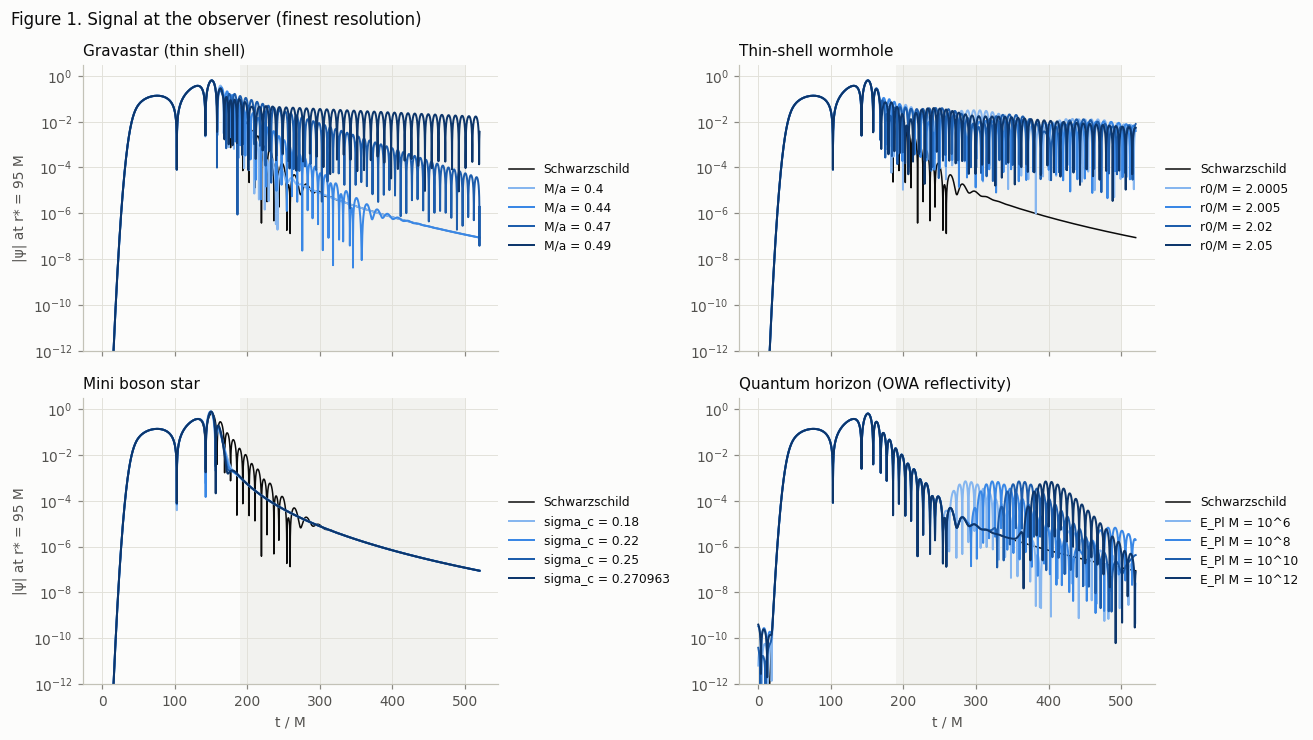

In [7]:
DATA = {}
for eid, e_ in ENTRIES.items():
    h_, a_ = ie.read_export(RESULTS / "entries" / f"{eid}.h5")
    c_ = a_["common"]
    levels = c_["correction"] if e_["model"] == "QH" else c_["eco"] - c_["bh"]    # residual at the three resolutions
    DATA[eid] = {"t": c_["t"], "eco": c_["eco"][2], "bh": c_["bh"][2], "res": levels, "header": h_, "arrays": a_}

def common_length(entries):
    return min(len(DATA[x["entry_id"]]["t"]) for x in entries)

if HAVE_MPL:
    fig, axes = plt.subplots(2, 2, figsize=(12, 6.8), sharex=True)
    for ax, model in zip(axes.flat, FAMILIES):
        ents = family(model)
        d0 = DATA[ents[0]["entry_id"]]
        ax.semilogy(d0["t"], np.abs(d0["bh"]), color=INK, lw=1.0, label="Schwarzschild")
        for colour, e_ in zip(RAMP, ents):
            d = DATA[e_["entry_id"]]
            ax.semilogy(d["t"], np.abs(d["eco"]), color=colour, label=label(e_))
        ax.axvspan(190, 500, color="#e1e0d9", alpha=0.35, lw=0)
        ax.set_ylim(1e-12, 3)
        ax.set_title(TITLES[model])
        ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
    for ax in axes[1]:
        ax.set_xlabel("t / M")
    for ax in axes[:, 0]:
        ax.set_ylabel("|ψ| at r* = 95 M")
    fig.suptitle("Figure 1. Signal at the observer (finest resolution)", x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

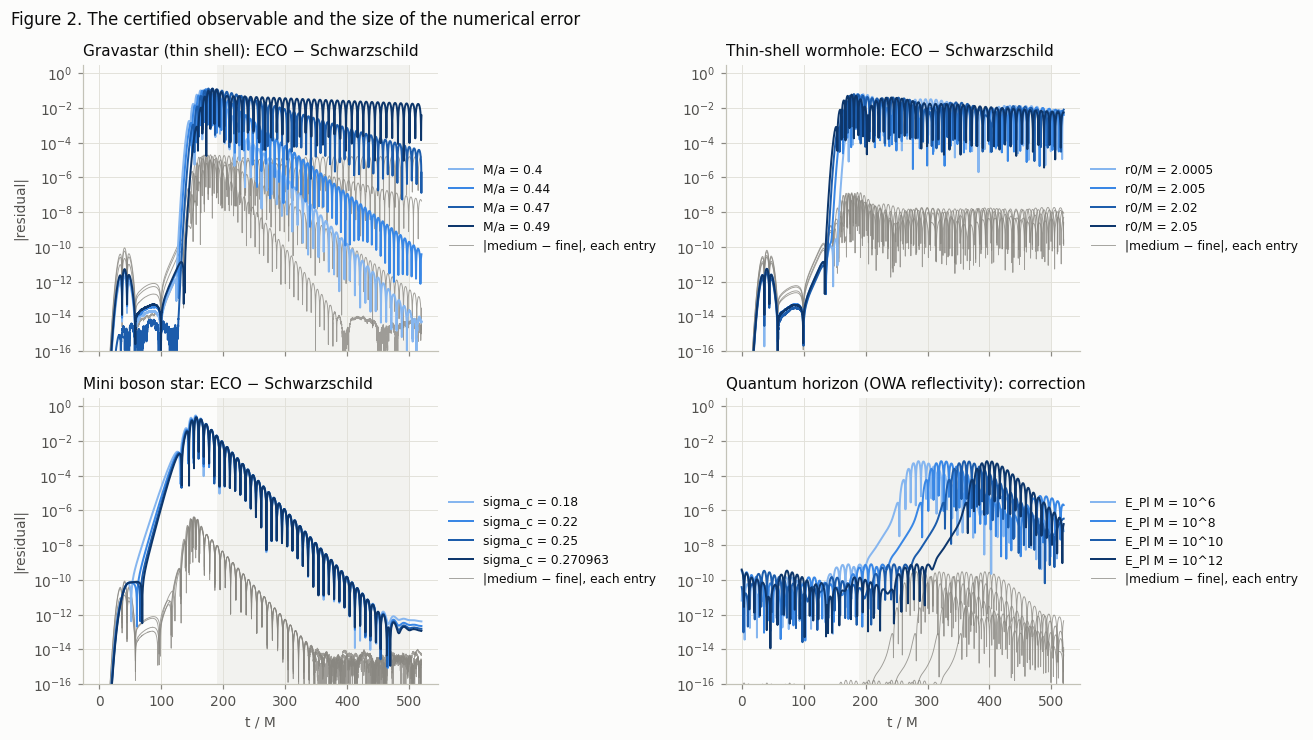

In [8]:
if HAVE_MPL:
    fig, axes = plt.subplots(2, 2, figsize=(12, 6.8), sharex=True)
    for ax, model in zip(axes.flat, FAMILIES):
        for k, e_ in enumerate(family(model)):       # each entry's own change between the two finest resolutions
            d = DATA[e_["entry_id"]]
            ax.semilogy(d["t"], np.abs(d["res"][1] - d["res"][2]), color=MUTED, lw=0.6, alpha=0.8,
                        label="|medium − fine|, each entry" if k == 0 else None)
        for colour, e_ in zip(RAMP, family(model)):
            d = DATA[e_["entry_id"]]
            ax.semilogy(d["t"], np.abs(d["res"][2]), color=colour, label=label(e_))
        ax.axvspan(190, 500, color="#e1e0d9", alpha=0.35, lw=0)
        ax.set_ylim(1e-16, 3)
        ax.set_title(TITLES[model] + (": correction" if model == "QH" else ": ECO − Schwarzschild"))
        handles, names = ax.get_legend_handles_labels()
        ax.legend(handles[1:] + handles[:1], names[1:] + names[:1], loc="center left", bbox_to_anchor=(1.0, 0.5))
    for ax in axes[1]:
        ax.set_xlabel("t / M")
    for ax in axes[:, 0]:
        ax.set_ylabel("|residual|")
    fig.suptitle("Figure 2. The certified observable and the size of the numerical error", x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

**Reading figures 1 and 2.**

* Up to the main burst (t ≈ 150 M) every signal is essentially the Schwarzschild one: the pulse has not
  yet reached the region where the objects differ. The differences appear when waves reflected inside
  the object reach the observer.
* **Gravastar.** At M/a = 0.40 and 0.44 the difference dies out within a few tens of M (decay times of
  the slowest verified mode: 9 M and 16 M) and the signal returns to the Schwarzschild power-law tail.
  At 0.47 the decay time is 40 M; at 0.49 it is 285 M, so the signal still rings at about 10⁻² when the
  record ends.
* **Wormhole.** All four throats trap waves between the potential barriers on the two sides. The
  slowest verified modes decay over 170 M (r₀/M = 2.05) to 1.5 × 10⁵ M (2.0005), so the residual stays
  near 10⁻² to the end: the 520 M records see only the start of the decay.
* **Boson star.** There is no trapped mode at these central fields: after the main burst the star rings
  briefly and the residual falls to about 10⁻¹² by 450 M. A small residual arrives even before the main
  burst, because the star's exterior is not exactly Schwarzschild (its scalar field decays exponentially
  with radius) and the incoming pulse is weakly scattered there.
* **Quantum horizon.** The correction is the part of the signal reflected by the horizon prescription.
  Before the first reflected packet it is about 10⁻¹⁰, the small acausal part of the reflectivity
  formula (`docs/VALIDATION.md`). The packet arrives later for larger E_Pl M (near 260, 300, 340 and
  375 M): the round trip to the effective reflecting surface grows by about 8 ln 100 ≈ 37 M per factor
  100. At 10⁶ and 10⁸ a second packet fits into the record.
* The grey curves lie orders of magnitude below the residuals wherever these are significant; section 5
  turns this into the acceptance number.

## 5. How accurate the numbers are

**Figure 3** shows the acceptance number of every entry (section 2), the numerical budget as a fraction
of the residual, in the late and full windows. The vertical line is the acceptance limit 0.1. Two
entries are inconclusive although their budget is small: they fail model-specific gates (section 3).
**Figure 4** shows the convergence behind one entry: the change from coarse to medium and from medium
to fine. For a method of order p the second is smaller by 2^p, so the scaled curve 2^p |m − f| lies on
top of |c − m|.

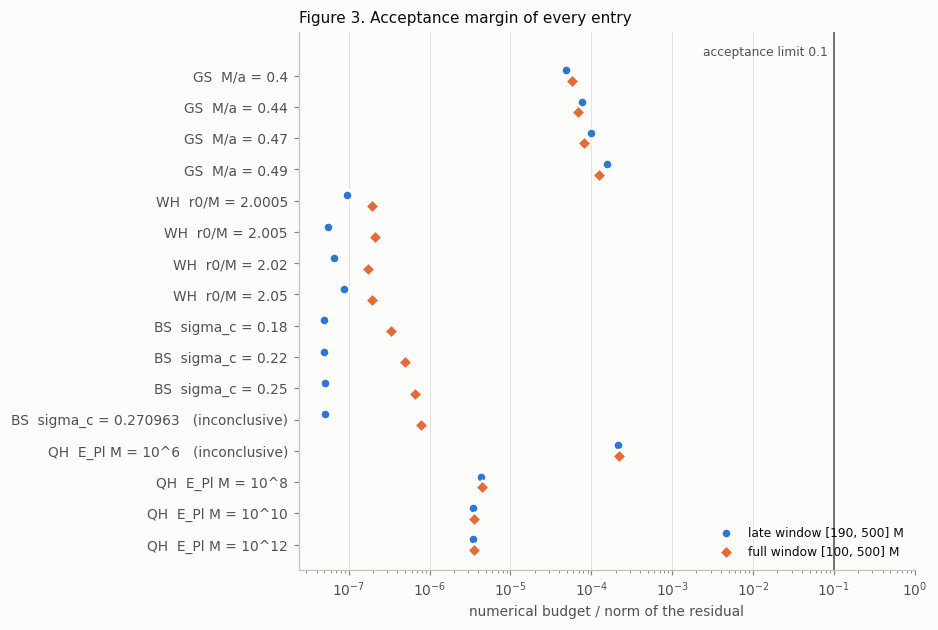

In [9]:
if HAVE_MPL:
    ents = [x for model in FAMILIES for x in family(model)]
    y = np.arange(len(ents))[::-1]
    fig, ax = plt.subplots(figsize=(8.6, 5.8))
    for window, colour, marker, dy in (("late", "#2a78d6", "o", 0.17), ("full", "#eb6834", "D", -0.17)):
        ax.scatter([x["observable_resolution"][window]["budget_fraction_of_norm"] for x in ents], y + dy, s=42,
                   color=colour, marker=marker, edgecolor=SURFACE, linewidth=1.5, zorder=3,
                   label=f"{window} window [{', '.join(f'{b:g}' for b in ents[0]['windows_M'][window])}] M")
    ax.axvline(0.1, color=INK2, lw=1.0)
    ax.text(0.085, y[0] + 0.55, "acceptance limit 0.1", color=INK2, fontsize=8, va="bottom", ha="right")
    ax.set_xscale("log")
    ax.set_xlim(right=1.0)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{x['model']}  {label(x)}" + ("   (inconclusive)" if x["state"] != "ACCEPTED_V1" else "")
                        for x in ents])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("numerical budget / norm of the residual")
    ax.set_ylim(-0.8, len(ents) + 0.4)
    ax.legend(loc="lower right")
    ax.set_title("Figure 3. Acceptance margin of every entry")
    fig.tight_layout()
    plt.show()

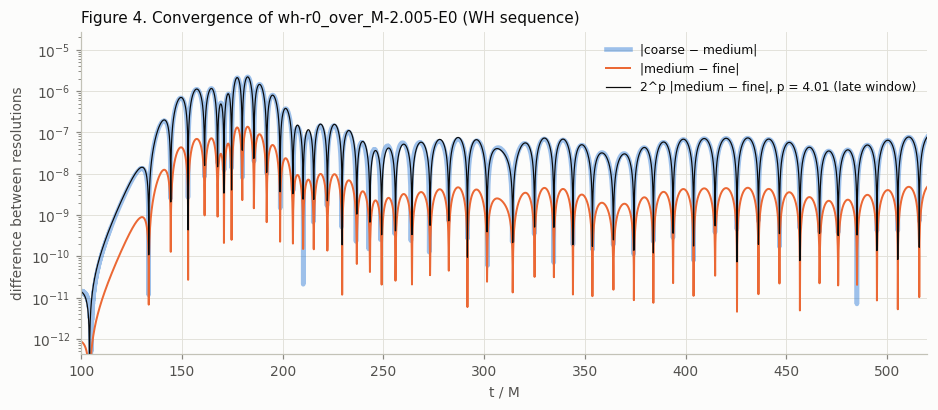

In [10]:
if HAVE_MPL:
    model = ENTRIES[DEMO]["model"]
    levels = DATA[DEMO]["arrays"]["common"]["correction" if model == "QH" else "eco"]
    name = "QH_CORRECTION" if model == "QH" else model
    p = ENTRIES[DEMO]["refinement"][name]["late"]["p_observed"]
    t_ = DATA[DEMO]["t"]
    fig, ax = plt.subplots(figsize=(8.6, 3.8))
    ax.semilogy(t_, np.abs(levels[0] - levels[1]), color="#2a78d6", lw=3.0, alpha=0.45, label="|coarse − medium|")
    ax.semilogy(t_, np.abs(levels[1] - levels[2]), color="#eb6834", label="|medium − fine|")
    ax.semilogy(t_, 2 ** p * np.abs(levels[1] - levels[2]), color=INK, lw=0.8,
                label=f"2^p |medium − fine|, p = {p:.2f} (late window)")
    later = np.abs(levels[1] - levels[2])[t_ >= 100]
    ax.set_ylim(np.percentile(later[later > 0], 2) / 10, None)
    ax.set_xlim(100, t_[-1])
    ax.set_xlabel("t / M")
    ax.set_ylabel("difference between resolutions")
    ax.legend(loc="upper right")
    ax.set_title(f"Figure 4. Convergence of {DEMO} ({name} sequence)")
    fig.tight_layout()
    plt.show()

## 6. Frequency-domain results (gravastar and wormhole)

The region between the inner surface (the gravastar shell, or the wormhole throat) and the potential
barrier acts as a cavity. **R_barrier** is the reflection coefficient of the barrier seen from inside,
**R_interface** that of the shell or throat; both are referenced at the seam, the shell or throat
position in r*. The group delay τ = d arg R / dω is the time a wave packet near frequency ω spends in a
reflection. τ_loop = τ_barrier + τ_interface is the round-trip time of the cavity, which sets the spacing
of trapped resonances. A delay is shown only where it is resolved (|R| ≥ 10⁻³ and numerical
uncertainty at most 10⁻⁶ max(|τ|, 1 M)); elsewhere it is left out, never interpolated. Every coefficient
array agrees with two numerical variants to better than 10⁻⁶, and so does an independent integration
(for the gravastar shell, the two variants are themselves an independent radial-ODE solution).

**Figure 6** shows the verified complex frequencies (quasinormal modes) of each entry, with the
Schwarzschild modes n = 0, 1, 2 for comparison. The lists are not exhaustive, and no ECO mode is
identified with a black-hole overtone.

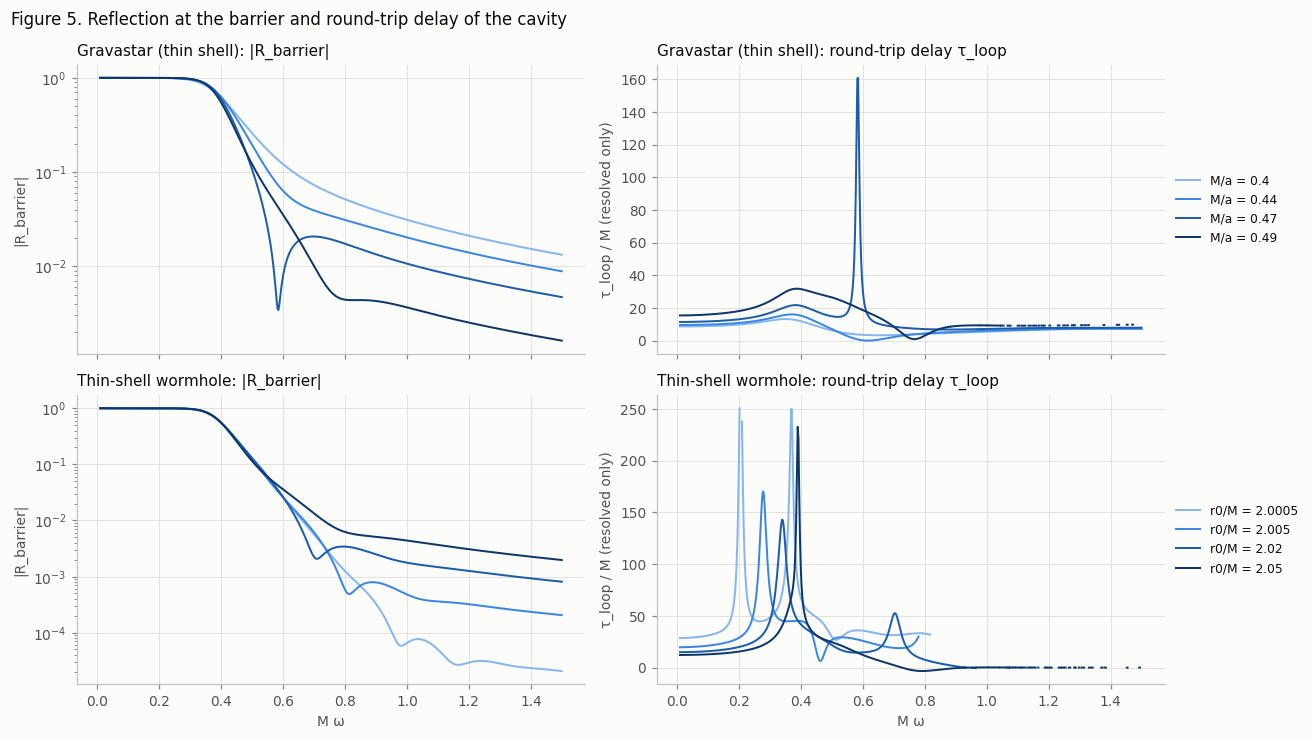

In [11]:
if HAVE_MPL:
    fig, axes = plt.subplots(2, 2, figsize=(12, 6.8), sharex=True)
    for row, model in zip(axes, ("GS", "WH")):
        for colour, e_ in zip(RAMP, family(model)):
            refl = DATA[e_["entry_id"]]["arrays"]["reflectivity"]
            w = refl["omega"]
            row[0].semilogy(w, np.abs(refl["R_barrier"]["R"]), color=colour, label=label(e_))
            resolved = (refl["R_barrier"]["tau_state_code"] == 0) & (refl["R_interface"]["tau_state_code"] == 0)
            tau_loop = np.where(resolved, refl["R_barrier"]["tau"] + refl["R_interface"]["tau"], np.nan)
            row[1].plot(w, tau_loop, color=colour, label=label(e_))
        row[0].set_title(f"{TITLES[model]}: |R_barrier|")
        row[1].set_title(f"{TITLES[model]}: round-trip delay τ_loop")
        row[0].set_ylabel("|R_barrier|")
        row[1].set_ylabel("τ_loop / M (resolved only)")
        row[1].legend(*row[0].get_legend_handles_labels(), loc="center left", bbox_to_anchor=(1.0, 0.5))
    for ax in axes[1]:
        ax.set_xlabel("M ω")
    fig.suptitle("Figure 5. Reflection at the barrier and round-trip delay of the cavity", x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

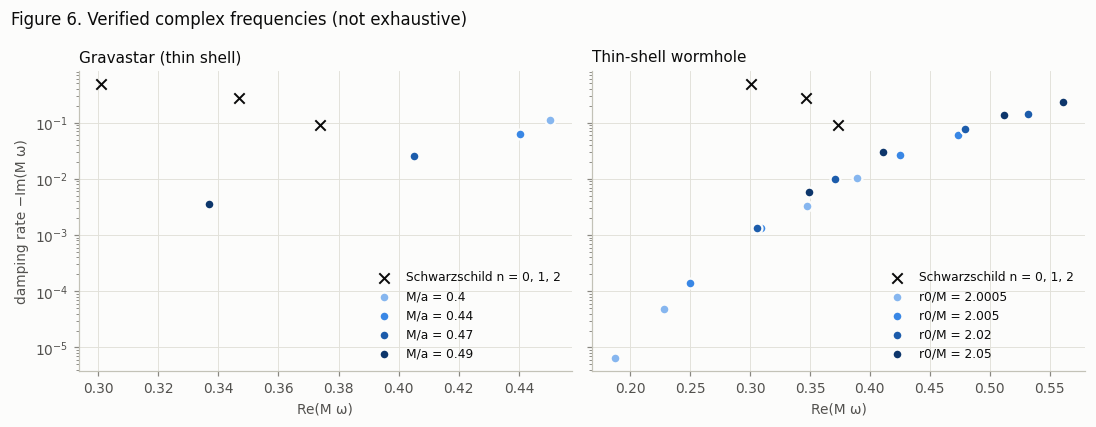

GS M/a = 0.4: 0.45020-1.11e-01i
GS M/a = 0.44: 0.44042-6.36e-02i
GS M/a = 0.47: 0.40510-2.50e-02i
GS M/a = 0.49: 0.33692-3.51e-03i
WH r0/M = 2.0005: 0.18692-6.62e-06i, 0.22813-4.76e-05i, 0.34712-3.25e-03i, 0.38897-1.05e-02i
WH r0/M = 2.005: 0.25023-1.38e-04i, 0.30905-1.35e-03i, 0.42537-2.69e-02i, 0.47365-6.04e-02i
WH r0/M = 2.02: 0.30604-1.33e-03i, 0.37061-1.00e-02i, 0.47906-7.60e-02i, 0.53192-1.41e-01i
WH r0/M = 2.05: 0.34946-5.89e-03i, 0.41130-2.96e-02i, 0.51172-1.37e-01i, 0.56096-2.30e-01i


In [12]:
import csv
bh_modes = [complex(row["Leaver"].strip("()")) for row in
            csv.DictReader(open("../baseline/eco_outputs_final/schwarzschild_qnms.csv", encoding="utf8"))]
if HAVE_MPL:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
    for ax, model in zip(axes, ("GS", "WH")):
        ax.scatter([w.real for w in bh_modes], [-w.imag for w in bh_modes], s=46, marker="x", color=INK,
                   label="Schwarzschild n = 0, 1, 2", zorder=3)
        for colour, e_ in zip(RAMP, family(model)):
            w = np.array([complex(*row["omega"]) for row in e_["modes"]["rows"]])
            ax.scatter(w.real, -w.imag, s=42, color=colour, edgecolor=SURFACE, linewidth=1.5, label=label(e_), zorder=3)
        ax.set_yscale("log")
        ax.set_xlabel("Re(M ω)")
        ax.set_title(TITLES[model])
        ax.legend(loc="lower right")
    axes[0].set_ylabel("damping rate −Im(M ω)")
    fig.suptitle("Figure 6. Verified complex frequencies (not exhaustive)", x=0.01, ha="left")
    fig.tight_layout()
    plt.show()
for model in ("GS", "WH"):
    for e_ in family(model):
        print(f"{model} {label(e_)}: " + ", ".join(f"{r_['omega'][0]:.5f}{r_['omega'][1]:+.2e}i" for r_ in e_["modes"]["rows"]))

**Reading figures 5 and 6.**

* Every barrier reflects almost totally below M ω ≈ 0.35 and becomes transparent above, as for a black
  hole. The coefficient depends on the object because it is measured at its seam; at M/a = 0.47 it has
  a near-zero at M ω ≈ 0.585, where its phase, and hence τ_loop, changes rapidly.
* The round-trip delay at low frequency grows as the surface approaches r = 2M: from about 9 M to 16 M
  for the gravastars (M/a = 0.40 to 0.49) and from 12 M to 29 M for the wormholes (r₀/M = 2.05 to
  2.0005).
* Breaks in a τ_loop curve are frequencies where the delay is not resolved; they are left out on purpose.
* The wormhole's two sides form two coupled cavities, so its modes come in even/odd pairs on either side
  of each peak of τ_loop (for r₀/M = 2.005: peak at M ω ≈ 0.278, modes at 0.250 and 0.309). Their damping
  falls by orders of magnitude as the throat approaches r = 2M. The gravastar's verified mode moves
  towards the real axis (lives longer) as the compactness grows.

## 7. Inside one library file

Each entry is one HDF5 file in `results/entries/`. A file holds a JSON header (the
catalogue state, identities, experiment, BH-reference details, per-window numbers, modes and coverage)
and an array tree: every resolution on its own native grid, the same levels on the common grid
t_k = 0.07 k M, and, for GS and WH, the reflection arrays. `read_export` checks the header, the manifest
and every array checksum before returning anything. Set `ECO_ENTRY` (or edit `ENTRY`) to open any other
entry; `show_entry` draws a one-entry summary.

In [13]:
ENTRY = os.environ.get("ECO_ENTRY", DEMO)
header, arrays = ie.read_export(RESULTS / "entries" / f"{ENTRY}.h5")
e = ENTRIES[ENTRY]
ids = header["identities"]
print(f"{ENTRY}: {header['catalogue_state']}; model {ids['model_definition']['model_id']}")
print("   scope:", ids["model_definition"]["scope"])
print(f"   entry identity {ids['entry_identity_sha256'][:16]}..., analysis parameter hash {ids['analysis_param_hash'][:16]}...")
print("   BH reference:", header["bh_reference"]["analysis_mode"], "| match:", header["bh_reference"]["match"],
      "| residual:", header["residual"]["source"])
print("   declared orders:", header["levels"]["declared_order"], "| refinement ratio", header["levels"]["ratio"])

def tree(node, indent="   "):
    for key, val in node.items():
        if isinstance(val, dict):
            print(f"{indent}{key}/")
            tree(val, indent + "    ")
        else:
            print(f"{indent}{key}: {val.dtype} {val.shape}")
print("\narrays:")
tree(arrays)

# The observable recomputed from the arrays in the library norm, against the catalogue:
t = arrays["common"]["t"]
obs = arrays["common"]["correction"][-1] if e["model"] == "QH" else arrays["common"]["eco"][-1] - arrays["common"]["bh"][-1]
for w in ("late", "full"):
    lo, hi = e["windows_M"][w]
    m = (t >= lo) & (t <= hi)
    value_ = float(np.sqrt(trapezoid(obs[m] ** 2, t[m])))
    cat = e["observable_resolution"][w]["norm_L2"]
    print(f"{w:5s} norm recomputed {value_:.10e}, catalogue {cat:.10e}, relative difference {abs(value_ - cat) / cat:.1e}")
print("audit of this file against its arrays and the catalogue:", ie.audit_export(header, arrays, e) or "no contradiction")

wh-r0_over_M-2.005-E0: ACCEPTED_V1; model WH/yang-xia-miao-thin-shell-schwarzschild-wormhole/axial-delta-throat
   scope: Yang-Xia-Miao thin-shell Schwarzschild wormhole with axial delta throat; not Damour-Solodukhin
   entry identity b74b0e2b79f9824e..., analysis parameter hash 003dc38c808bae61...
   BH reference: MATCHED_RESOLUTION | match: {'domain': False, 'dt': False, 'extraction': False, 'grid': False, 'solver': True} | residual: ECO_MINUS_MATCHED_BH
   declared orders: {'bh': 4, 'eco': 4, 'residual': 4} | refinement ratio 2.0

arrays:
   common/
       bh: float64 (3, 7428)
       eco: float64 (3, 7428)
       t: float64 (7428,)
   native/
       bh_coarse/
           psi: float64 (3715,)
           t: float64 (3715,)
       bh_fine/
           psi: float64 (14858,)
           t: float64 (14858,)
       bh_medium/
           psi: float64 (7430,)
           t: float64 (7430,)
       eco_coarse/
           psi: float64 (3715,)
           t: float64 (3715,)
       eco_fine/
       

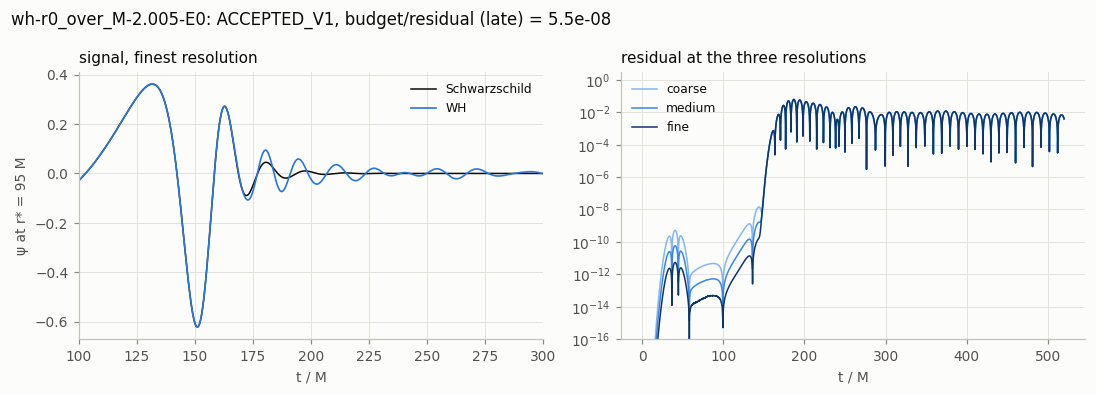

In [14]:
def show_entry(entry_id):
    """One-entry summary: the signal against Schwarzschild, and the residual at the three resolutions."""
    d, x = DATA[entry_id], ENTRIES[entry_id]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
    a1.plot(d["t"], d["bh"], color=INK, lw=1.0, label="Schwarzschild")
    a1.plot(d["t"], d["eco"], color="#2a78d6", lw=1.1, label=x["model"])
    a1.set_xlim(100, 300)
    a1.set_xlabel("t / M")
    a1.set_ylabel("ψ at r* = 95 M")
    a1.set_title("signal, finest resolution")
    a1.legend(loc="upper right")
    for k, (colour, name) in enumerate(zip(("#86b6ef", "#3987e5", "#0d366b"), ("coarse", "medium", "fine"))):
        a2.semilogy(d["t"], np.abs(d["res"][k]), color=colour, lw=1.0, label=name)
    a2.set_ylim(1e-16, 3)
    a2.set_xlabel("t / M")
    a2.set_title("residual at the three resolutions")
    a2.legend(loc="upper left")
    frac = x["observable_resolution"]["late"]["budget_fraction_of_norm"]
    fig.suptitle(f"{entry_id}: {x['state']}, budget/residual (late) = {frac:.1e}", x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

if HAVE_MPL:
    show_entry(ENTRY)          # e.g. show_entry("gs-compactness-0.49-E0") or show_entry("qh-EplM-1e+10-E0")

## 8. Checking everything, and where to look next

The cell below re-derives every status of the catalogue from the evidence stored beside it (the status
audit), and checks every result file against the index and its own arrays. The same checks, and the
complete reproduction, run from the command line:

```
python -m eco_library audit       # this cell's checks and the frozen-notebook hash (seconds)
python -m pytest tests -q         # the test suite
python -m eco_library reproduce   # recompute everything from the frozen equations into runs/
python -m eco_library compare     # compare the reproduction with results/
```

In [15]:
problems = catalogue.status_audit(CATALOGUE)
print("status audit of the catalogue:", "no contradiction" if not problems else problems)
index = json.loads((RESULTS / "entries-index.json").read_text(encoding="utf8"))
ok = {}
for entry_id, row in index["exports"].items():
    path = RESULTS / "entries" / row["file"]
    h_, a_ = ie.read_export(path)
    ok[entry_id] = ie.index_row(path, h_) == row and not ie.audit_export(h_, a_, ENTRIES[entry_id])
print(f"{sum(ok.values())} of {len(ok)} result files match the index and pass their audit")
assert not problems and all(ok.values())

status audit of the catalogue: no contradiction


16 of 16 result files match the index and pass their audit


**Where to look next.**

| What | Where |
|---|---|
| The results, and what can and cannot be concluded | `docs/RESULTS.md` |
| Equations, computation and acceptance rule | `docs/METHOD.md` |
| Every check and its outcome, and how to reproduce | `docs/VALIDATION.md` |
| All numbers, machine-readable | `results/catalogue.json`; the supporting studies in `results/checks/` |
| Waveforms, residuals, reflection coefficients | `results/entries/` (this section) |
| The code and its tests | `eco_library/`, `tests/`, `scripts/` |
| Raw simulation records | not stored: `python -m eco_library reproduce` writes them to `runs/` |

**Limits.** One experiment (one pulse shape and observer) and four points per family; numerical
estimates are conditional Richardson estimates with controls, not error bounds. The models are axial
l = 2 only: no polar sector and no rotation; BS on a fixed background; QH is a prescription and is
validated only for E_Pl M from 10⁸ to 10¹². Records end at 520 M, which does not cover the slow decay
of the wormholes or later QH packets. The BS waveform has no independent-method check, and the BS poles
are withdrawn. The library makes no echo classification, detectability statement or black-hole
overtone identification; those are later stages of the project.